# Monetary Policy Reaction Function

## Alcance y pregunta

¿Ignorar suavizamiento confunde reacción de corto y largo plazo?

**Laboratorio estructural sintético.** La ampliación semanal sustituye el baseline OLS genérico por un experimento del mecanismo anunciado. No contiene estimaciones de datos de Colombia ni evidencia de desempeño productivo.

## Modelo y mecanismo

$$i_t=\rho i_{t-1}+(1-\rho)(\phi_\pi\pi_t+\phi_x x_t)+u_t$$

La regla de política usa φπ=1.5, φx=0.5 y suavizamiento ρ. La regresión dinámica identifica el coeficiente de inflación de largo plazo dividiendo el coeficiente corto por 1−ρ estimado.

### Supuestos de identificación

Inflación y brecha exógenas iid en este experimento; sin simultaneidad ni límite inferior de tasas.

La verdad del DGP es conocida por construcción. Recuperar esa verdad comprueba implementación y diseño; no establece que el mecanismo describa una población observada.

## Configuración reproducible

Se usan NumPy, SciPy, Pandas y Matplotlib del entorno de investigación del repositorio. La semilla es fija, todos los cálculos se ejecutan desde los inputs y ninguna celda lee resultados precomputados. OLS incluye intercepto salvo fórmulas que lo excluyen explícitamente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
COLORS=['#245C83','#B56A20','#637843']
SEED=20261018
REPLICATIONS=40

def ols_fit(y, regressors):
    """Intercept included; QR/SVD-backed least squares, no matrix inversion."""
    X=np.column_stack([np.ones(len(y)),regressors])
    coefficients,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('Diseño sin rango completo')
    return coefficients,y-X@coefficients

def ar_process(rng,n,rho):
    if abs(rho)>=1: raise ValueError('Se requiere AR estacionario')
    draws=rng.normal(size=n+200); x=np.zeros(n+200)
    for t in range(1,len(x)): x[t]=rho*x[t-1]+draws[t]
    return x[200:]


## Datos y experimento

La regla de política usa φπ=1.5, φx=0.5 y suavizamiento ρ. La regresión dinámica identifica el coeficiente de inflación de largo plazo dividiendo el coeficiente corto por 1−ρ estimado.

El siguiente código define el DGP o problema de equilibrio y sus comparadores. Las restricciones, oráculos analíticos y condiciones de factibilidad que corresponden al mecanismo se comprueban dentro de la función. Las cantidades monetarias se expresan en unidades sintéticas.

In [2]:
def experiment(rng,level,n=900):
    inflation=rng.normal(size=n); gap=rng.normal(size=n); rate=np.zeros(n)
    noise=rng.normal(scale=.15,size=n)
    for t in range(1,n):rate[t]=level*rate[t-1]+(1-level)*(1.5*inflation[t]+.5*gap[t])+noise[t]
    static=ols_fit(rate[1:],np.column_stack([inflation[1:],gap[1:]]))[0][1]
    dynamic=ols_fit(rate[1:],np.column_stack([rate[:-1],inflation[1:],gap[1:]]))[0]
    return {'OLS estático':static,'Reacción de largo plazo':dynamic[2]/(1-dynamic[1]),'Reacción real':1.5},(np.arange(n),rate)


### Un escenario reproducible

Cada métrica conserva su denominador y unidad conceptual; no se mezclan conteos, probabilidades y costos en un mismo eje. La tabla muestra el caso central de la malla, antes de resumir réplicas.

In [3]:
GRID=[0, 0.3, 0.6, 0.8, 0.95]
METRICS=['OLS estático', 'Reacción de largo plazo', 'Reacción real']
central=GRID[len(GRID)//2]
example,diagnostic=experiment(np.random.default_rng(SEED),central)
display(pd.DataFrame({'Métrica':list(example),'Valor':list(example.values())}))
print('Escenario central:',central,'; semilla:',SEED)


Escenario central: 0.6 ; semilla: 20261018


,Métrica,Valor
0,OLS estático,0.599366
1,Reacción de largo plazo,1.527927
2,Reacción real,1.500000


## Sensibilidad y variación entre réplicas

**Eje:** Suavizamiento de tasas.

Se conservan 40 réplicas por escenario. Se reinicia la misma secuencia de semillas para cada nivel: las comparaciones entre niveles comparten innovaciones cuando la dimensión del DGP lo permite. En mecanismos deterministas los cuantiles coinciden; esto no representa una incertidumbre estimada de parámetros. No se descartan resultados desfavorables.

In [4]:
records=[]
for level in GRID:
    for replicate in range(REPLICATIONS):
        metrics,_=experiment(np.random.default_rng(SEED+replicate),level)
        if set(metrics)!=set(METRICS): raise AssertionError('Métricas inconsistentes')
        for name,value in metrics.items():
            if not np.isfinite(value):raise ArithmeticError(f'Resultado no finito: {name}')
            records.append({'nivel':level,'replica':replicate,'metrica':name,'valor':float(value)})
raw=pd.DataFrame(records)
summary=raw.groupby(['nivel','metrica'],sort=False).valor.agg(
    media='mean',mediana='median',sd_replicas='std',
    q025=lambda x:x.quantile(.025),q975=lambda x:x.quantile(.975),n='size').reset_index()
summary['se_media_mc']=summary.sd_replicas/np.sqrt(summary.n)
display(summary.round(5))


,nivel,metrica,media,mediana,sd_replicas,q025,q975,n,se_media_mc
0,0.00,OLS estático,1.50065,1.50050,0.00526,1.49205,1.51349,40,0.00083
1,0.00,Reacción de largo plazo,1.50054,1.50052,0.00634,1.48905,1.51157,40,0.00100
2,0.00,Reacción real,1.50000,1.50000,0.00000,1.50000,1.50000,40,0.00000
3,0.30,OLS estático,1.05207,1.05131,0.00993,1.03312,1.06788,40,0.00157
4,0.30,Reacción de largo plazo,1.50014,1.49996,0.01037,1.48208,1.51926,40,0.00164
5,0.30,Reacción real,1.50000,1.50000,0.00000,1.50000,1.50000,40,0.00000
6,0.60,OLS estático,0.60141,0.59990,0.01477,0.57672,0.62958,40,0.00234
7,0.60,Reacción de largo plazo,1.49822,1.49479,0.02332,1.46803,1.54674,40,0.00369
8,0.60,Reacción real,1.50000,1.50000,0.00000,1.50000,1.50000,40,0.00000
9,0.80,OLS estático,0.29971,0.29877,0.01772,0.26750,0.33599,40,0.00280


### Qué muestran los intervalos

Las bandas de la figura son cuantiles 2.5–97.5% entre realizaciones del DGP, **no intervalos de confianza de un estimador en una sola muestra**. `se_media_mc` mide únicamente el error Monte Carlo de la media en este conjunto de réplicas; no mide incertidumbre económica ni corrige especificación. Se informa media y mediana para detectar asimetría, especialmente bajo identificación débil.

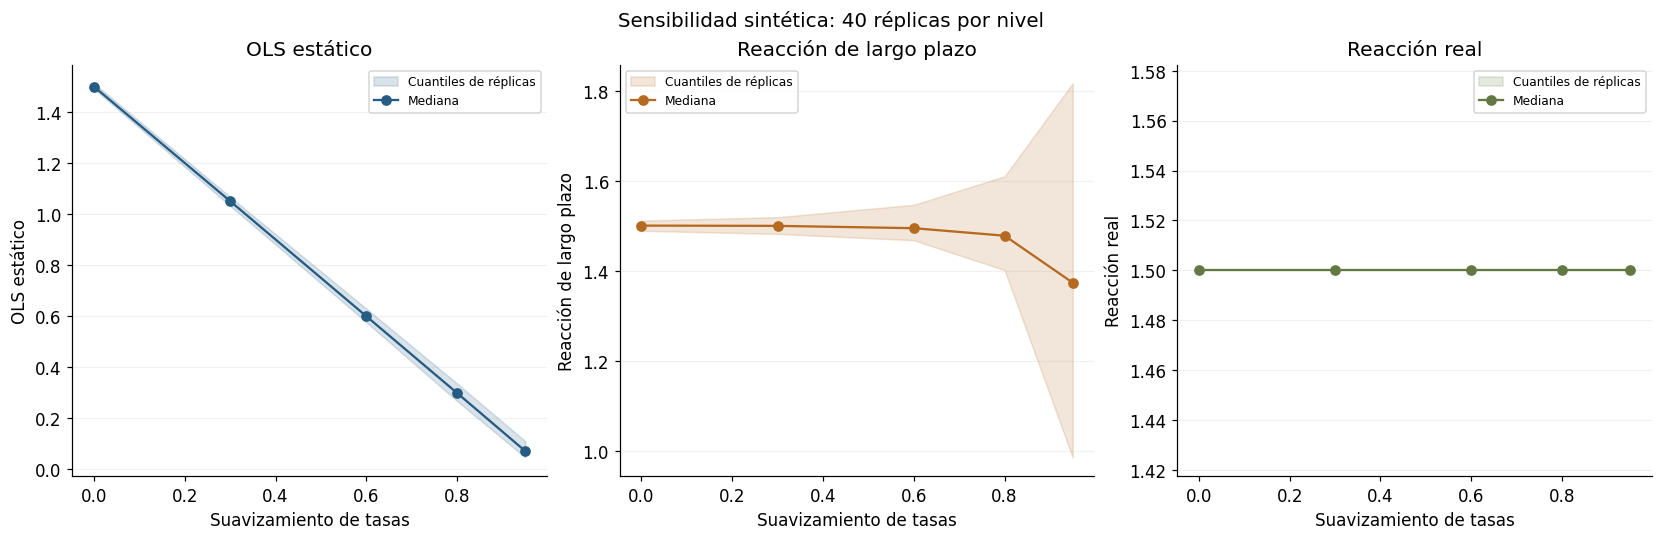

In [5]:
import textwrap
fig,axes=plt.subplots(1,len(METRICS),figsize=(15,4.8),layout='constrained')
for index,(ax,name) in enumerate(zip(np.atleast_1d(axes),METRICS)):
    group=summary[summary.metrica==name].sort_values('nivel')
    ax.fill_between(group.nivel,group.q025,group.q975,color=COLORS[index%3],alpha=.17,label='Cuantiles de réplicas')
    ax.plot(group.nivel,group.mediana,'o-',color=COLORS[index%3],label='Mediana')
    ax.set(title='\n'.join(textwrap.wrap(name,25)),xlabel='\n'.join(textwrap.wrap('Suavizamiento de tasas',30)),ylabel=name)
    ax.grid(axis='y',alpha=.18); ax.legend(fontsize=8)
fig.suptitle('Sensibilidad sintética: 40 réplicas por nivel',fontsize=13)
plt.show()


## Lectura de resultados ejecutados

El contraste siguiente se calcula con las salidas de la ejecución, sin fijar de antemano el signo de la conclusión. Debe interpretarse junto con los supuestos y la variación entre réplicas.

In [6]:
for name in METRICS:
    group=summary[summary.metrica==name].sort_values('nivel')
    first,last=group.iloc[0],group.iloc[-1]
    print(f"{name}: mediana {first['mediana']:.6g} en nivel {first['nivel']:g}; "
          f"{last['mediana']:.6g} en nivel {last['nivel']:g}.")
    print(f"  Último escenario: cuantiles [{last['q025']:.6g}, {last['q975']:.6g}], "
          f"media {last['media']:.6g}, error MC de la media {last['se_media_mc']:.3g}.")


OLS estático: mediana 1.5005 en nivel 0; 0.0712491 en nivel 0.95.
  Último escenario: cuantiles [0.046448, 0.110081], media 0.0726615, error MC de la media 0.00266.
Reacción de largo plazo: mediana 1.50052 en nivel 0; 1.37375 en nivel 0.95.
  Último escenario: cuantiles [0.985736, 1.81667], media 1.41096, error MC de la media 0.0387.
Reacción real: mediana 1.5 en nivel 0; 1.5 en nivel 0.95.
  Último escenario: cuantiles [1.5, 1.5], media 1.5, error MC de la media 0.


## Comprobaciones y controles

La reproducibilidad exige que la misma semilla reconstruya las mismas métricas. Los asserts estructurales de la función no dependen de que un estimador estocástico gane a otro en esta realización. Los conteos se reconcilian para no perder réplicas silenciosamente.

In [7]:
repeated,_=experiment(np.random.default_rng(SEED),central)
assert all(np.isclose(example[k],repeated[k],rtol=0,atol=1e-12) for k in METRICS)
assert len(raw)==len(GRID)*REPLICATIONS*len(METRICS)
assert summary.n.eq(REPLICATIONS).all()
assert (summary.q025<=summary.mediana+1e-12).all()
assert (summary.mediana<=summary.q975+1e-12).all()
print('Semilla, finitud, cuantiles y totalidad de réplicas: correctos.')


Semilla, finitud, cuantiles y totalidad de réplicas: correctos.


## Límites y siguiente contraste

Una reacción estimada no identifica efectos causales de política. Cerca de ρ=1 el cociente de largo plazo es inestable.

Antes de incorporar datos observados se debe fijar unidad de análisis, fecha de disponibilidad, reglas de exclusión y población de evaluación. La ampliación demuestra un mecanismo acotado; no convierte el proyecto en modelo validado externamente.

## Trazabilidad

Desarrollo semanal sobre `865c326`, revisión del 18-10-2026 UTC (noche del 17-10 en Colombia). El historial Git conserva el baseline genérico anterior. Todos los datos nuevos se regeneran desde la función `experiment`; las salidas del notebook se guardan después de ejecutar sus celdas de principio a fin.